In [1]:
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
import joblib

In [2]:
df = pd.read_csv('Beans Multiclass Classification.csv')

In [3]:
df.head()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [4]:
df.tail()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
13606,42097,759.696,288.721612,185.944705,1.552728,0.765002,42508,231.515799,0.714574,0.990331,0.916603,0.801865,0.006858,0.001749,0.642988,0.998385,DERMASON
13607,42101,757.499,281.576392,190.713136,1.476439,0.735702,42494,231.526798,0.799943,0.990752,0.922015,0.822252,0.006688,0.001886,0.676099,0.998219,DERMASON
13608,42139,759.321,281.539928,191.187979,1.472582,0.734065,42569,231.631261,0.729932,0.989899,0.918424,0.822730,0.006681,0.001888,0.676884,0.996767,DERMASON
13609,42147,763.779,283.382636,190.275731,1.489326,0.741055,42667,231.653247,0.705389,0.987813,0.907906,0.817457,0.006724,0.001852,0.668237,0.995222,DERMASON
13610,42159,772.237,295.142741,182.204716,1.619841,0.786693,42600,231.686223,0.788962,0.989648,0.888380,0.784997,0.007001,0.001640,0.616221,0.998180,DERMASON


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  str    
dtypes: float64(14), int64(2

In [6]:
df.columns

Index(['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength',
       'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent',
       'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2',
       'ShapeFactor3', 'ShapeFactor4', 'Class'],
      dtype='str')

In [7]:
df.describe()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
count,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000
mean,53048.284549,855.283459,320.141867,202.270714,1.583242,0.750895,53768.200206,253.064220,0.749733,0.987143,0.873282,0.799864,0.006564,0.001716,0.643590,0.995063
std,29324.095717,214.289696,85.694186,44.970091,0.246678,0.092002,29774.915817,59.177120,0.049086,0.004660,0.059520,0.061713,0.001128,0.000596,0.098996,0.004366
min,20420.000000,524.736000,183.601165,122.512653,1.024868,0.218951,20684.000000,161.243764,0.555315,0.919246,0.489618,0.640577,0.002778,0.000564,0.410339,0.947687
25%,36328.000000,703.523500,253.303633,175.848170,1.432307,0.715928,36714.500000,215.068003,0.718634,0.985670,0.832096,0.762469,0.005900,0.001154,0.581359,0.993703
50%,44652.000000,794.941000,296.883367,192.431733,1.551124,0.764441,45178.000000,238.438026,0.759859,0.988283,0.883157,0.801277,0.006645,0.001694,0.642044,0.996386
75%,61332.000000,977.213000,376.495012,217.031741,1.707109,0.810466,62294.000000,279.446467,0.786851,0.990013,0.916869,0.834270,0.007271,0.002170,0.696006,0.997883
max,254616.000000,1985.370000,738.860154,460.198497,2.430306,0.911423,263261.000000,569.374358,0.866195,0.994677,0.990685,0.987303,0.010451,0.003665,0.974767,0.999733


In [8]:
df.value_counts()

Area   Perimeter  MajorAxisLength  MinorAxisLength  AspectRation  Eccentricity  ConvexArea  EquivDiameter  Extent    Solidity  roundness  Compactness  ShapeFactor1  ShapeFactor2  ShapeFactor3  ShapeFactor4  Class   
33518  702.956    277.571399       154.305581       1.798842      0.831240      34023       206.582775     0.808383  0.985157  0.852377   0.744251     0.008281      0.001567      0.553909      0.996396      HOROZ       2
33954  716.750    277.368480       156.356326       1.773951      0.825970      34420       207.922042     0.799482  0.986461  0.830549   0.749624     0.008169      0.001591      0.561936      0.996847      HOROZ       2
38427  756.323    306.533886       160.591784       1.908777      0.851782      38773       221.193978     0.796976  0.991076  0.844174   0.721597     0.007977      0.001334      0.520702      0.993905      HOROZ       2
38891  791.343    319.499996       156.869619       2.036723      0.871168      39651       222.525412     0.650025  0.98

In [9]:
df.dtypes

Area                 int64
Perimeter          float64
MajorAxisLength    float64
MinorAxisLength    float64
AspectRation       float64
Eccentricity       float64
ConvexArea           int64
EquivDiameter      float64
Extent             float64
Solidity           float64
roundness          float64
Compactness        float64
ShapeFactor1       float64
ShapeFactor2       float64
ShapeFactor3       float64
ShapeFactor4       float64
Class                  str
dtype: object

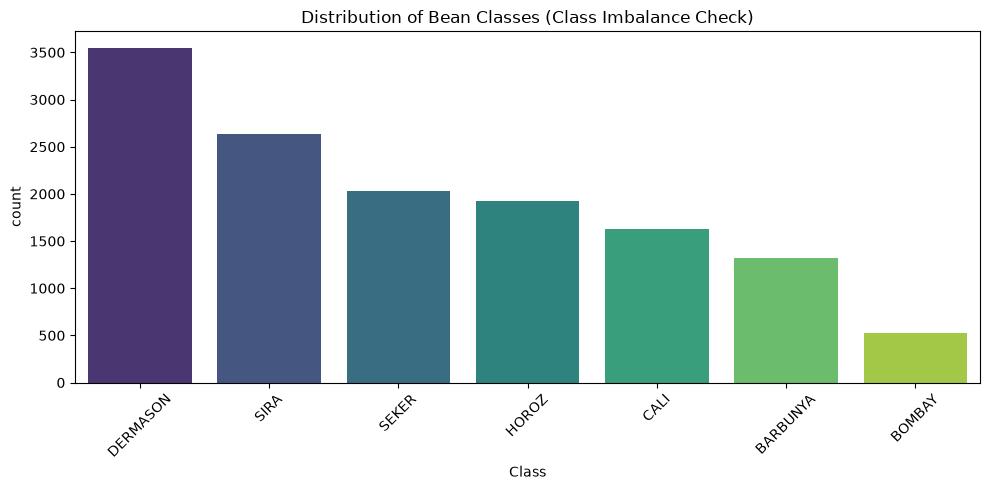

In [10]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='Class', order=df['Class'].value_counts().index, palette='viridis')
plt.title('Distribution of Bean Classes (Class Imbalance Check)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

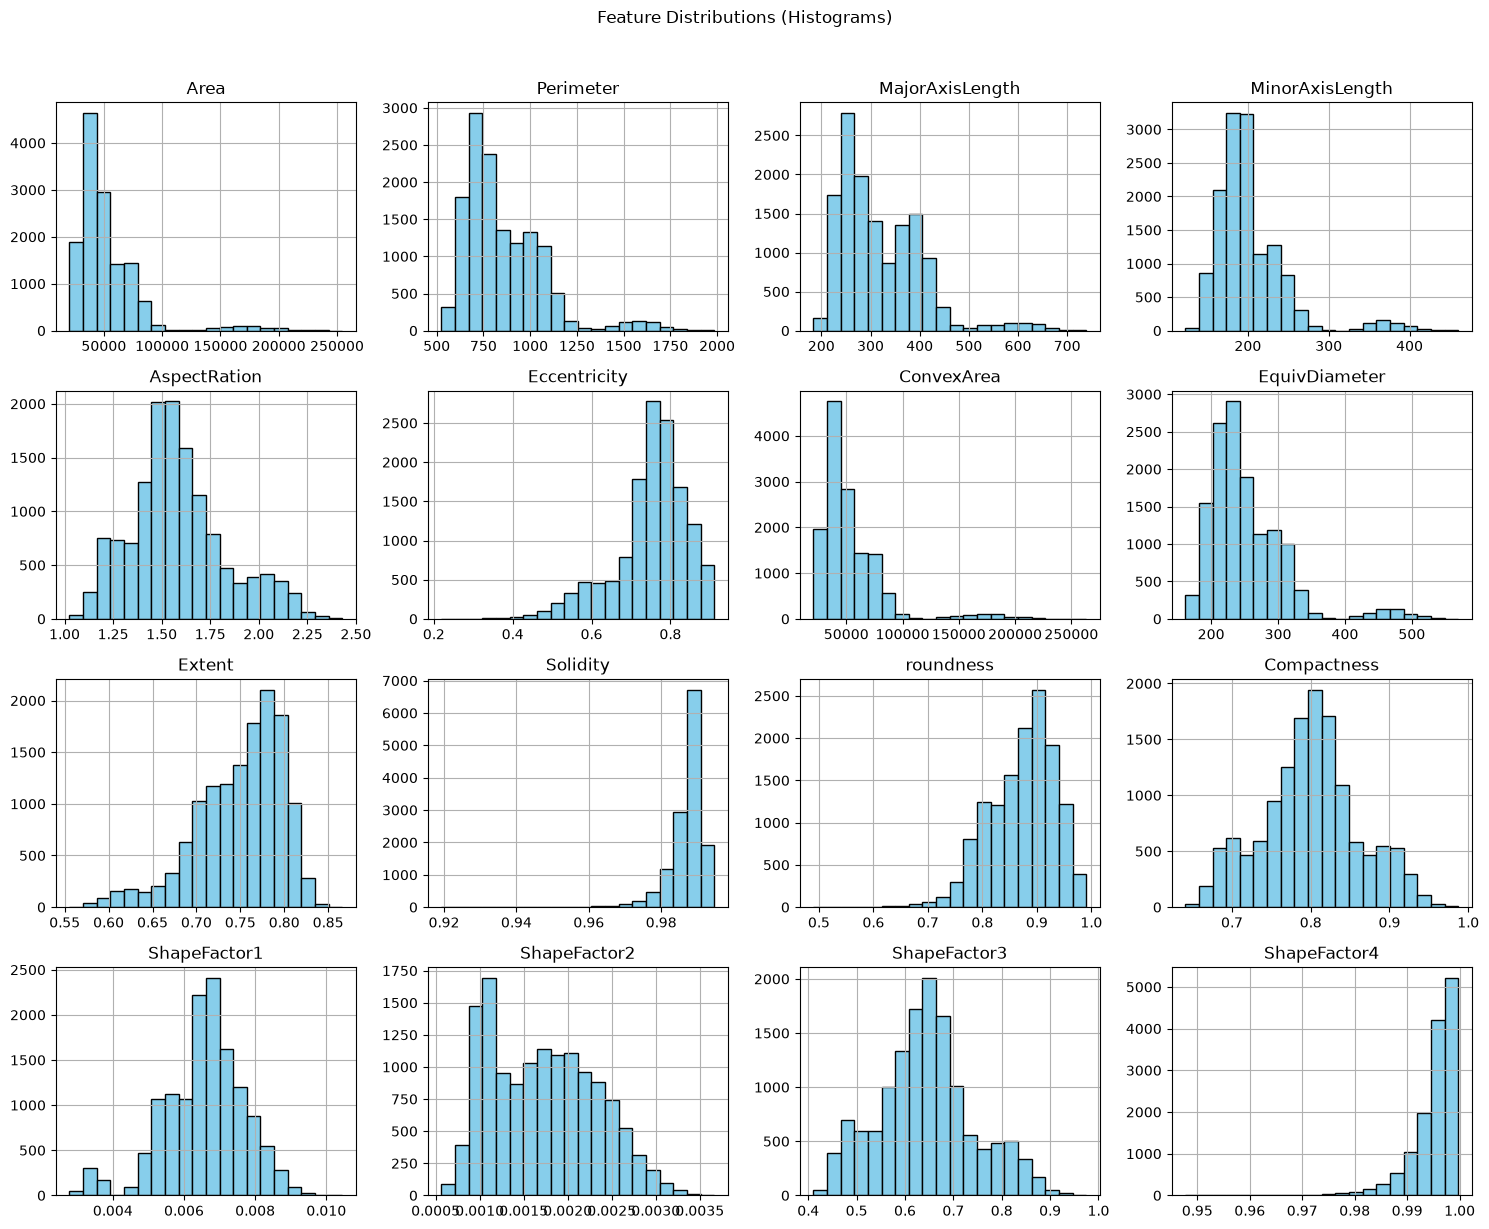

In [11]:
df.hist(bins=20, figsize=(15, 12), color='skyblue', edgecolor='black')
plt.suptitle('Feature Distributions (Histograms)', y=1.02)
plt.tight_layout()
plt.show()

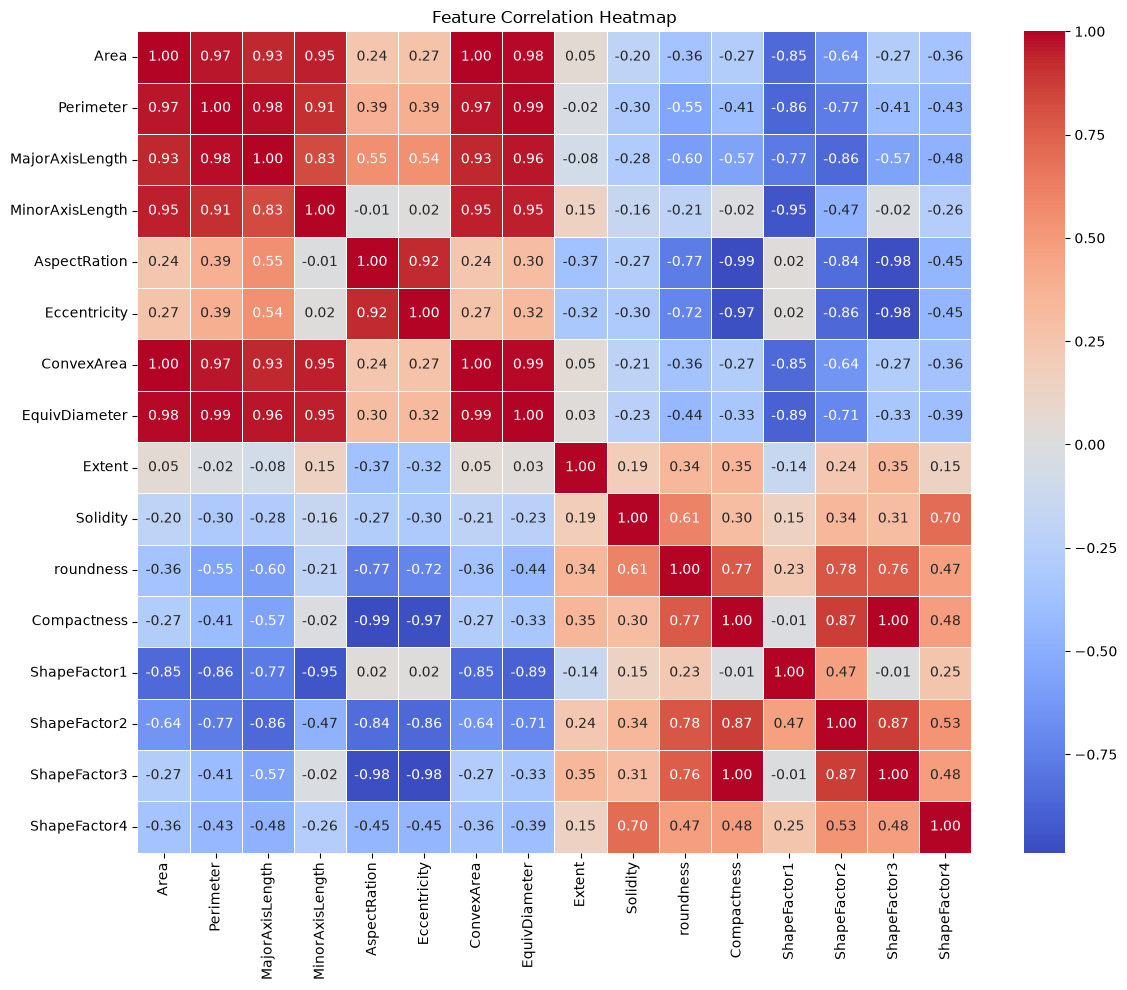

In [12]:
plt.figure(figsize=(12, 10))
numeric_df = df.drop(columns=['Class'])
corr_matrix = numeric_df.corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.show()

In [13]:
print("Missing values count per column:")
print(df.isnull().sum())

Missing values count per column:
Area               0
Perimeter          0
MajorAxisLength    0
MinorAxisLength    0
AspectRation       0
Eccentricity       0
ConvexArea         0
EquivDiameter      0
Extent             0
Solidity           0
roundness          0
Compactness        0
ShapeFactor1       0
ShapeFactor2       0
ShapeFactor3       0
ShapeFactor4       0
Class              0
dtype: int64


In [14]:
numeric_cols = df.select_dtypes(include=[np.number]).columns
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    # Capping outliers
    df[col] = np.where(df[col] < lower_bound, lower_bound, df[col])
    df[col] = np.where(df[col] > upper_bound, upper_bound, df[col])
print("Outliers treated successfully using IQR capping.")

Outliers treated successfully using IQR capping.


In [15]:
X = df.drop(columns=['Class'])
y = df['Class']

In [16]:
le = LabelEncoder()
y_encoded = le.fit_transform(y)

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

In [18]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [19]:
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_scaled, y_train)
print(f"Original training shape: {X_train_scaled.shape}")
print(f"Resampled training shape: {X_train_resampled.shape}")

Original training shape: (10888, 16)
Resampled training shape: (19859, 16)


In [20]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "SVM": SVC(random_state=42),
    "KNN": KNeighborsClassifier(),
    "Naive Bayes": GaussianNB()
}

results_summary = []

for name, model in models.items():
    
    model.fit(X_train_resampled, y_train_resampled)
    
    
    y_train_pred = model.predict(X_train_resampled)
    y_test_pred = model.predict(X_test_scaled)
    
    
    train_acc = accuracy_score(y_train_resampled, y_train_pred)
    test_acc = accuracy_score(y_test, y_test_pred)
    f1 = f1_score(y_test, y_test_pred, average='weighted')
    
    
    overfitting = "Y" if (train_acc - test_acc) > 0.05 else "N"
    
    results_summary.append({
        "Model": name,
        "Train Accuracy": round(train_acc * 100, 2),
        "Test Accuracy": round(test_acc * 100, 2),
        "F1 Score": round(f1, 4),
        "Overfitting (Y/N)": overfitting
    })
    
    print(f"\n--- {name} ---")
    print(f"Test Accuracy: {test_acc:.4f} | F1-Score: {f1:.4f}")


--- Logistic Regression ---
Test Accuracy: 0.9199 | F1-Score: 0.9202

--- Decision Tree ---
Test Accuracy: 0.8961 | F1-Score: 0.8960

--- Random Forest ---
Test Accuracy: 0.9218 | F1-Score: 0.9217

--- SVM ---
Test Accuracy: 0.9236 | F1-Score: 0.9237

--- KNN ---
Test Accuracy: 0.9130 | F1-Score: 0.9130

--- Naive Bayes ---
Test Accuracy: 0.9001 | F1-Score: 0.9004


In [21]:
print("\n--- Hyperparameter Tuning (Random Forest) ---")
param_grid = {
    'n_estimators': [50, 100],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5]
}

grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42), 
    param_grid, 
    cv=3, 
    scoring='f1_weighted', 
    n_jobs=-1
)
grid_search.fit(X_train_resampled, y_train_resampled)

best_rf = grid_search.best_estimator_
best_rf_pred = best_rf.predict(X_test_scaled)
best_test_acc = accuracy_score(y_test, best_rf_pred)
best_f1 = f1_score(y_test, best_rf_pred, average='weighted')

print(f"Best Parameters: {grid_search.best_params_}")
print(f"Tuned Random Forest Test Accuracy: {best_test_acc:.4f}")
print(f"Tuned Random Forest F1-Score: {best_f1:.4f}")


--- Hyperparameter Tuning (Random Forest) ---
Best Parameters: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 100}
Tuned Random Forest Test Accuracy: 0.9218
Tuned Random Forest F1-Score: 0.9217


In [22]:
results_summary.append({
    "Model": "Best Model (Tuned RF)",
    "Train Accuracy": round(accuracy_score(y_train_resampled, best_rf.predict(X_train_resampled)) * 100, 2),
    "Test Accuracy": round(best_test_acc * 100, 2),
    "F1 Score": round(best_f1, 4),
    "Overfitting (Y/N)": "N"
})

In [23]:
print("\n--- Model Comparison Table ---")
comparison_df = pd.DataFrame(results_summary)
print(comparison_df.to_string(index=False))


--- Model Comparison Table ---
                Model  Train Accuracy  Test Accuracy  F1 Score Overfitting (Y/N)
  Logistic Regression           94.14          91.99    0.9202                 N
        Decision Tree          100.00          89.61    0.8960                 Y
        Random Forest          100.00          92.18    0.9217                 Y
                  SVM           94.81          92.36    0.9237                 N
                  KNN           96.91          91.30    0.9130                 Y
          Naive Bayes           91.11          90.01    0.9004                 N
Best Model (Tuned RF)          100.00          92.18    0.9217                 N


In [24]:
joblib.dump(best_rf, 'best_bean_model.pkl')
joblib.dump(scaler, 'scaler.pkl')
joblib.dump(le, 'label_encoder.pkl')

['label_encoder.pkl']